In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from tqdm import tqdm

from src import IS_CUPY_BACKEND, xp
from src.logging_utils import setup_logging
from src.problems.lorenz96 import lorenz96, lorenz96_grad
from src.surrogate import HATANNSurrogate

setup_logging()

# --- CONSTANTS LORENZ96 ---
DIM = 5
FORCING = 1.0
TOL = 0.01
TF_STEP = 0.01
N_TRAIN = 200_000

cwd = Path.cwd()
model_path = (
    cwd
    / "models"
    / f"lorenz96_dim{DIM}_F{FORCING}_ntrain{N_TRAIN}_tol{TOL}_tf{TF_STEP}.npz"
)


def flowmap_with_sensitivity(x0, tf):
    """
    Computes flowmap and sensitivity (Jacobian) for a single initial condition x0.
    Adapts single vector inputs to the (N, D) interface required by lorenz96 functions.
    """
    d = len(x0)
    # initial_condition: [state(d), flattened_jacobian(d*d)]
    initial_condition = np.hstack([x0, np.eye(d).flatten()])

    def sensitivity_ode(t, y):
        # 1. Unpack the state vector from the solver (1D array)
        x = y[:d]
        J = y[d:].reshape((d, d))

        # 2. Reshape x to (1, D) for the batch-expecting functions
        x_batch = x.reshape(1, -1)

        # 3. Call user functions
        # returns (1, D) -> take [0]
        dxdt = lorenz96(x_batch)[0]
        # returns (1, D, D) -> take [0]
        jac = lorenz96_grad(x_batch)[0]

        # 4. Compute sensitivity derivative: dJ/dt = df/dx * J
        dJdt = jac @ J

        # 5. Flatten everything back to 1D for the solver
        return np.hstack([dxdt, dJdt.flatten()])

    # Tight tolerances are crucial for sensitivity analysis
    sol = solve_ivp(
        sensitivity_ode,
        [0, tf],
        initial_condition,
        method="RK45",
        rtol=1e-10,
        atol=1e-12,
    )

    yf = sol.y[:, -1]
    return yf[:d], yf[d:].reshape((d, d))


def batch_flowmap_grad(X0, tf):
    """
    Wraps the single-instance flowmap solver to handle a batch of inputs X0 (N, D).
    """
    N, d = X0.shape
    XF = np.zeros((N, d))
    GF = np.zeros((N, d, d))

    # Loop over the batch (solve_ivp is not naturally vectorized across samples)
    for i in tqdm(range(N), desc="Computing flowmap with sensitivity"):
        XF[i], GF[i] = flowmap_with_sensitivity(X0[i], tf)

    return XF, GF


# Update initialization range for Lorenz96 (it tends to stay closer to forcing term)
X_train_cpu = np.random.uniform(-10, 10, size=(N_TRAIN, DIM)) + FORCING
X_train = xp.asarray(X_train_cpu) if IS_CUPY_BACKEND else X_train_cpu
surrogate = HATANNSurrogate(version="v2")


def lorenz_oracle(x):
    xf, gf = batch_flowmap_grad(x, tf=TF_STEP)
    return xp.asarray(xf), xp.asarray(gf)


print(f"Training Surrogate for Lorenz96 (Dim={DIM}, F={FORCING})...")
surrogate.train(
    X_train=X_train,
    oracle_fn=lorenz_oracle,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=200,
    USE_HESSIAN_INFORMED_SPLIT=True,
    ERROR_METRIC="Linf-local",
    save_model=model_path,
    load_if_exists=True,
)

/home/prajwal/github-repos/knnsur/src/__init__.py:18: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


2026-02-03 06:38:44 - root - INFO - Logging to file: /home/prajwal/github-repos/knnsur/.logs/20260203_063844.log
Training Surrogate for Lorenz96 (Dim=5, F=1.0)...


Computing flowmap with sensitivity:   4%|▎         | 7341/200000 [00:10<04:30, 712.69it/s]


KeyboardInterrupt: 

In [ ]:
%matplotlib widget

<>:96: SyntaxWarning: invalid escape sequence '\e'
<>:96: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_138980/2186150816.py:96: SyntaxWarning: invalid escape sequence '\e'
  label=f"Perturbed ($\epsilon={PERT_EPS}$)",


ODE Integration Time: 0.1090 seconds
Surrogate Prediction Time: 0.0085 seconds
Speedup: 12.78x (Steps: 100)


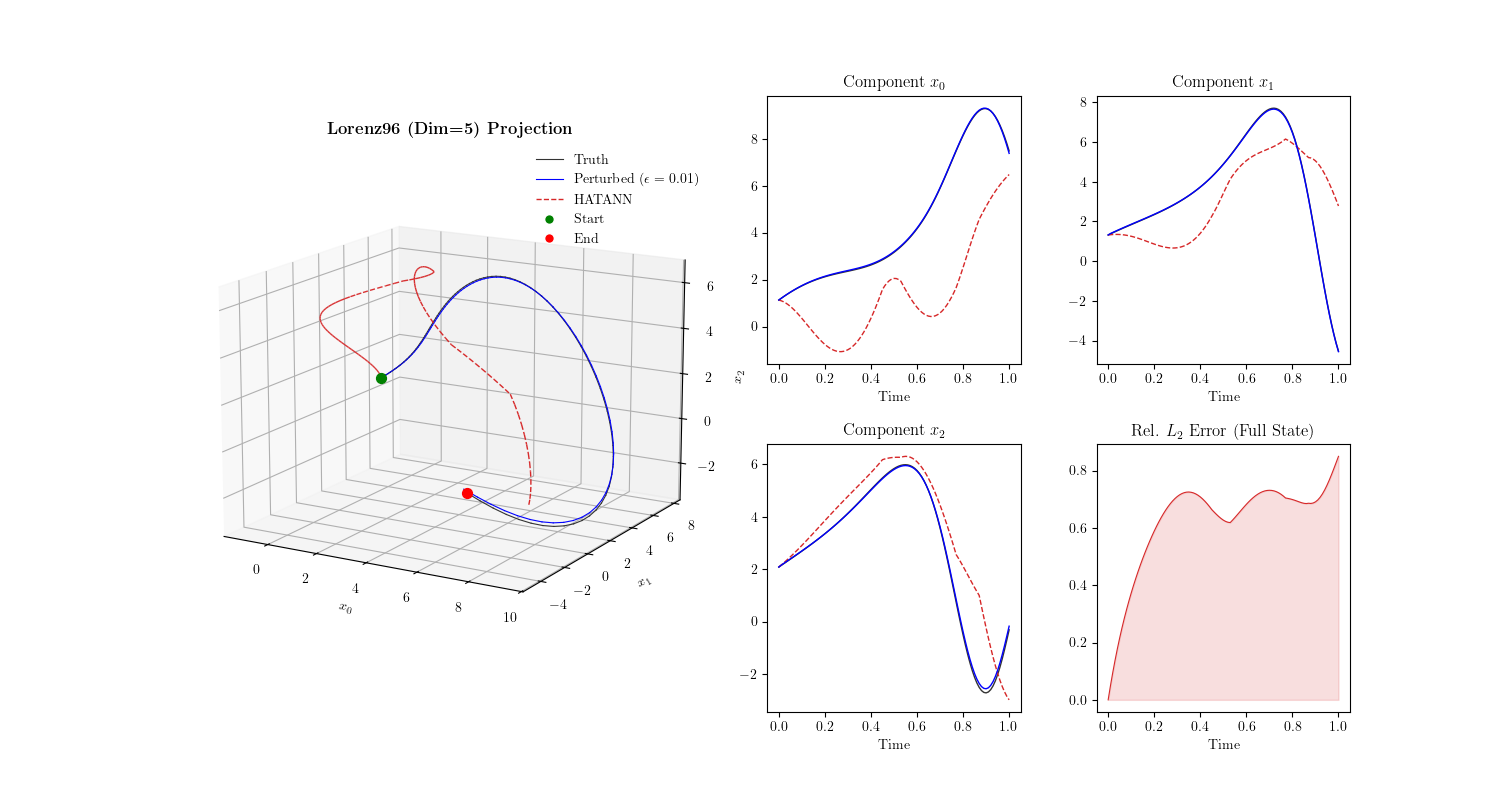

In [ ]:
PREDICT_TIME = 1
PERT_EPS = 1e-2
# Recursive Simulation with finer steps
STEPS = int(PREDICT_TIME / TF_STEP)
t_axis = np.linspace(0, PREDICT_TIME, STEPS + 1)

# Initialize a random start near the forcing equilibrium
x0 = np.random.randn(1, DIM) + FORCING

true_path, surr_path, small_perturbed = [x0[0]], [x0[0]], [x0[0]]
curr_true, curr_surr = x0, xp.asarray(x0) if IS_CUPY_BACKEND else x0
curr_perturbed = x0 + PERT_EPS * np.random.randn(1, DIM)

_time_ode = 0
_time_sur = 0
for _ in range(STEPS):
    _tic = time.perf_counter()
    curr_true, _ = batch_flowmap_grad(curr_true, tf=TF_STEP)
    _time_ode += time.perf_counter() - _tic
    true_path.append(curr_true[0])

    _tic = time.perf_counter()
    pred, _ = surrogate.predict(curr_surr, k_nn=1)
    _time_sur += time.perf_counter() - _tic
    curr_surr = pred
    surr_path.append(pred[0])

    curr_perturbed, _ = batch_flowmap_grad(curr_perturbed, tf=TF_STEP)
    small_perturbed.append(curr_perturbed[0])


true = np.array(true_path).T
surr = np.array(surr_path).T
curr_perturbed = np.array(small_perturbed).T


# Plotting
plt.rcParams.update(
    {"text.usetex": True, "font.family": "serif", "figure.figsize": (15, 8)}
)
fig = plt.figure()
gs = GridSpec(1, 2, width_ratios=[0.9, 1], wspace=0.1)

# 3D Phase Space (First 3 components)
ax3d = fig.add_subplot(gs[0], projection="3d")

n_points = true.shape[1]
alphas = np.linspace(0.9, 1.0, n_points)
for i in range(n_points - 1):
    # Truth
    ax3d.plot(
        true[0, i : i + 2],
        true[1, i : i + 2],
        true[2, i : i + 2],
        color="#333333",
        lw=0.8,
        alpha=alphas[i],
    )
    # Surrogate
    ax3d.plot(
        surr[0, i : i + 2],
        surr[1, i : i + 2],
        surr[2, i : i + 2],
        color="#d62728",
        ls="--",
        lw=1.0,
        alpha=alphas[i],
    )
    # Perturbed
    ax3d.plot(
        curr_perturbed[0, i : i + 2],
        curr_perturbed[1, i : i + 2],
        curr_perturbed[2, i : i + 2],
        color="blue",
        ls="-",
        lw=0.8,
        alpha=alphas[i],
    )

ax3d.scatter(true[0, 0], true[1, 0], true[2, 0], color="green", s=50, label="Start")
ax3d.scatter(true[0, -1], true[1, -1], true[2, -1], color="red", s=50, label="End")
ax3d.view_init(elev=15, azim=-60)
ax3d.set_title(rf"\textbf{{Lorenz96 (Dim={DIM}) Projection}}")
ax3d.set_xlabel("$x_0$")
ax3d.set_ylabel("$x_1$")
ax3d.set_zlabel("$x_2$")

legend_elements = [
    Line2D([0], [0], color="#333333", lw=0.8, label="Truth"),
    Line2D(
        [0],
        [0],
        color="blue",
        ls="-",
        lw=0.8,
        label=f"Perturbed ($\epsilon={PERT_EPS}$)",
    ),
    Line2D([0], [0], color="#d62728", ls="--", lw=1.0, label="HATANN"),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="green",
        markersize=7,
        label="Start",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="red",
        markersize=7,
        label="End",
    ),
]
ax3d.legend(handles=legend_elements, frameon=False, loc="upper right")

# Components and Error
gs_sub = gs[1].subgridspec(2, 2, hspace=0.3, wspace=0.3)
labels = ["x_0", "x_1", "x_2"]

# Plot only first 3 components
for i in range(3):
    ax = fig.add_subplot(gs_sub[i // 2, i % 2])
    ax.plot(t_axis, true[i], color="#333333", lw=1)
    ax.plot(t_axis, surr[i], color="#d62728", ls="--", lw=1)
    ax.plot(t_axis, curr_perturbed[i], color="blue", ls="-", lw=1)
    ax.set_title(f"Component ${labels[i]}$")
    ax.set_xlabel("Time")

# Error Plot
ax_err = fig.add_subplot(gs_sub[1, 1])
err = np.linalg.norm(true - surr, axis=0) / (np.linalg.norm(true, axis=0) + 1e-10)
ax_err.fill_between(t_axis, err, color="#d62728", alpha=0.15)
ax_err.plot(t_axis, err, color="#d62728", lw=0.8)
ax_err.set_title(r"Rel. $L_2$ Error (Full State)")
ax_err.set_xlabel("Time")

print(f"ODE Integration Time: {_time_ode:.4f} seconds")
print(f"Surrogate Prediction Time: {_time_sur:.4f} seconds")
print(f"Speedup: {_time_ode / _time_sur:.2f}x (Steps: {STEPS:,})")
plt.show()